In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt
import seaborn as sns
sns.set(style= "darkgrid", color_codes = True)
from tensorflow.keras.applications import VGG16
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import  Dense, Flatten, Dropout, Input, GlobalAveragePooling2D
from keras.regularizers import l2
import warnings
warnings.filterwarnings('ignore')
tf.config.optimizer.set_jit(False)
# Vérifier si GPU est disponible
if tf.config.list_physical_devices('GPU'):
    # Permettre la croissance de la mémoire GPU
    for gpu in tf.config.experimental.list_physical_devices('GPU'):
        tf.config.experimental.set_memory_growth(gpu, True)
print("GPU disponible:", tf.config.list_physical_devices('GPU'))

2025-04-07 15:35:05.109194: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2025-04-07 15:35:05.126402: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1744032905.142511   35605 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1744032905.147355   35605 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1744032905.164989   35605 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking 

GPU disponible: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
# Define image size and other parameters
img_width, img_height = 128, 128
batchsize = 32
epochs = 6
num_of_class = 2
def create_three_class_dataset(directory, batch_size, img_size):
    # Créer une liste de tous les fichiers
    import os
    
    normal_path = os.path.join(directory, 'NORMAL')
    pneumonia_path = os.path.join(directory, 'PNEUMONIA')
    
    # Préparer les listes de fichiers et leurs labels
    normal_files = [(f, [1,0,0]) for f in os.listdir(normal_path) if f.endswith(('.jpeg', '.jpg', '.png'))]
    pneumonia_files = []
    for f in os.listdir(pneumonia_path):
        if f.endswith(('.jpeg', '.jpg', '.png')):
            if 'virus' in f.lower():
                pneumonia_files.append((f, [0,1,0]))  # Viral
            elif 'bacteria' in f.lower():
                pneumonia_files.append((f, [0,0,1]))  # Bacterial
    
    # Fonction pour charger et prétraiter une image
    def load_and_preprocess_image(file_path):
        img = tf.io.read_file(file_path)
        img = tf.image.decode_jpeg(img, channels=3)
        img = tf.image.resize(img, img_size)
        img = img / 255.0  # Normalisation
        return img
    
    # Créer les datasets séparés
    normal_dataset = tf.data.Dataset.from_tensor_slices(
        ([os.path.join(normal_path, f[0]) for f in normal_files],
         [f[1] for f in normal_files]))
    
    pneumonia_dataset = tf.data.Dataset.from_tensor_slices(
        ([os.path.join(pneumonia_path, f[0]) for f in pneumonia_files],
         [f[1] for f in pneumonia_files]))
    
    # Combiner les datasets
    dataset = normal_dataset.concatenate(pneumonia_dataset)
    
    # Mapper pour charger les images
    dataset = dataset.map(lambda x, y: (load_and_preprocess_image(x), y))
    
    # Mélanger et créer les batches
    dataset = dataset.shuffle(buffer_size=1000)
    dataset = dataset.batch(batch_size)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)
    
    return dataset

# Charger les datasets
img_size = (img_width, img_height)
train = create_three_class_dataset('chest_xray/train', batchsize, img_size)
validation = create_three_class_dataset('chest_xray/val', batchsize, img_size)
test = create_three_class_dataset('chest_xray/test', batchsize, img_size)

# Vérifier la forme des données
for images, labels in train.take(1):
    print("Images shape:", images.shape)
    print("Labels shape:", labels.shape)
    print("Sample labels:", labels[0])  # Devrait montrer un vecteur one-hot de taille 3

I0000 00:00:1744032909.994084   35605 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 3539 MB memory:  -> device: 0, name: NVIDIA RTX 1000 Ada Generation Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9


Images shape: (32, 128, 128, 3)
Labels shape: (32, 3)
Sample labels: tf.Tensor([1 0 0], shape=(3,), dtype=int32)


2025-04-07 15:35:11.382679: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


Format des labels: [1 0 0]
Label 0: [1.0, 0.0, 0.0]
Label 1: [1.0, 0.0, 0.0]
Label 2: [1.0, 0.0, 0.0]
Label 3: [1.0, 0.0, 0.0]


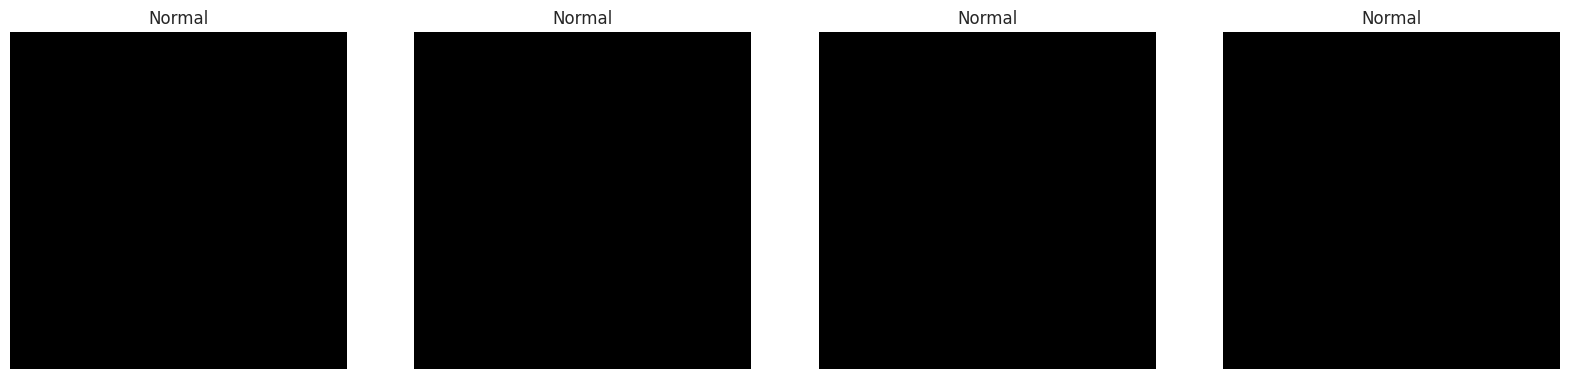

In [3]:
data_iterator = train.as_numpy_iterator()
batch = data_iterator.next()

# Afficher un exemple de label pour debug
print("Format des labels:", batch[1][0])

# Créer un dictionnaire pour convertir les labels one-hot en texte
label_dict = {
    '[1.0, 0.0, 0.0]': "Normal",
    '[0.0, 1.0, 0.0]': "Viral Pneumonia",
    '[0.0, 0.0, 1.0]': "Bacterial Pneumonia"
}

fig, ax = plt.subplots(ncols=4, figsize=(20,20))
for idx, img in enumerate(batch[0][:4]):
    ax[idx].imshow(img.astype(int))
    # Convertir le label en string avec le bon format
    label_str = str([float(x) for x in batch[1][idx].tolist()])
    print(f"Label {idx}:", label_str)  # Debug
    label = label_dict.get(label_str, "Unknown")
    ax[idx].title.set_text(label)
    ax[idx].axis('off')

plt.show()

In [4]:
from tensorflow.keras.utils import to_categorical
# Définir une taille fixe pour toutes les images
IMG_SIZE = (128, 128)  # Taille standard pour VGG16

# Extracting Features and Labels
x_train = []
y_train = []
x_val = []
y_val = []
x_test = []
y_test = []

# Fonction pour traiter un batch
def process_batch(batch):
    features, labels = batch
    features = tf.image.resize(features, IMG_SIZE)
    return features.numpy(), labels.numpy()

# Traiter les données d'entraînement
for batch in train:
    features, labels = process_batch(batch)
    x_train.extend(features)
    y_train.extend(labels)

# Traiter les données de test
for batch in test:
    features, labels = process_batch(batch)
    x_test.extend(features)
    y_test.extend(labels)

# Traiter les données de validation
for batch in validation:
    features, labels = process_batch(batch)
    x_val.extend(features)
    y_val.extend(labels)

# Convertir en arrays numpy
x_train = np.array(x_train, dtype=np.float32)
x_val = np.array(x_val, dtype=np.float32)
x_test = np.array(x_test, dtype=np.float32)
y_train = np.array(y_train, dtype=np.float32)
y_val = np.array(y_val, dtype=np.float32)
y_test = np.array(y_test, dtype=np.float32)

# Normaliser les images
x_train = tf.image.resize(x_train, IMG_SIZE)
x_val = tf.image.resize(x_val, IMG_SIZE)
x_test = tf.image.resize(x_test, IMG_SIZE)


# Vérifier les shapes
print("Shape de x_train:", x_train.shape)
print("Shape de y_train:", y_train.shape)
print("Shape de x_val:", x_val.shape)
print("Shape de y_val:", y_val.shape)
print("Shape de x_test:", x_test.shape)
print("Shape de y_test:", y_test.shape)

# Vérifier les valeurs uniques dans les labels
print("\nValeurs uniques dans y_train:", np.unique(y_train, axis=0))

2025-04-07 15:35:17.555590: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence
2025-04-07 15:35:18.134520: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


Shape de x_train: (5216, 128, 128, 3)
Shape de y_train: (5216, 3)
Shape de x_val: (16, 128, 128, 3)
Shape de y_val: (16, 3)
Shape de x_test: (624, 128, 128, 3)
Shape de y_test: (624, 3)

Valeurs uniques dans y_train: [[0. 0. 1.]
 [0. 1. 0.]
 [1. 0. 0.]]


In [5]:
# check the shapes of 'x_train' and 'y_train':
print("Shape of 'x_train':", x_train.shape)
print("Shape of 'y_train':", y_train.shape)
print("Shape of 'x_val':", x_val.shape)
print("Shape of 'y_val':", y_val.shape)
print("Shape of 'x_test':", x_test.shape)
print("Shape of 'y_test':", y_test.shape)

Shape of 'x_train': (5216, 128, 128, 3)
Shape of 'y_train': (5216, 3)
Shape of 'x_val': (16, 128, 128, 3)
Shape of 'y_val': (16, 3)
Shape of 'x_test': (624, 128, 128, 3)
Shape of 'y_test': (624, 3)


In [6]:
def create_model():
    base_model = VGG16(weights='imagenet', 
                      include_top=False, 
                      input_shape=(128, 128, 3))
    
    for layer in base_model.layers:
        layer.trainable = False
    
    
    model = Sequential([
        base_model,
        Flatten(),
        Dropout(0.4),
        Dense(256, activation='relu', kernel_regularizer=l2(0.01)),
        Dropout(0.3),
        Dense(128, activation='relu', kernel_regularizer=l2(0.01)),
        Dense(3, activation='softmax')
    ])
    
    # Learning rate plus faible pour un meilleur apprentissage
    optimizer = tf.keras.optimizers.Adam(learning_rate=0.0001)
    
    model.compile(
        optimizer=optimizer,
        loss='categorical_crossentropy',
        metrics=['accuracy', 'Precision', 'Recall']
    )

    model.summary()
    
    return model

Fold 1/5


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 4, 4, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     2,097,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,845,379 (64.26 MB)

 Trainable params: 2,130,691 (8.13 MB)

...

  3/131 ━━━━━━━━━━━━━━━━━━━━ 6s 54ms/step - Precision: 0.3541 - Recall: 0.3299 - accuracy: 0.3628 - loss: 8.5438

I0000 00:00:1744032932.854697   35766 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 89ms/step - Precision: 0.5904 - Recall: 0.4191 - accuracy: 0.5442 - loss: 6.6844

2025-04-07 15:35:49.793648: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_276', 4 bytes spill stores, 4 bytes spill loads



131/131 ━━━━━━━━━━━━━━━━━━━━ 33s 172ms/step - Precision: 0.5911 - Recall: 0.4198 - accuracy: 0.5448 - loss: 6.6769 - val_Precision: 0.7950 - val_Recall: 0.7280 - val_accuracy: 0.7797 - val_loss: 4.1249 - learning_rate: 1.0000e-04
Epoch 2/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 9s 66ms/step - Precision: 0.7489 - Recall: 0.6764 - accuracy: 0.7185 - loss: 3.8695 - val_Precision: 0.8014 - val_Recall: 0.7615 - val_accuracy: 0.7874 - val_loss: 3.0315 - learning_rate: 1.0000e-04
Epoch 3/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 9s 66ms/step - Precision: 0.7868 - Recall: 0.7289 - accuracy: 0.7577 - loss: 2.9342 - val_Precision: 0.8108 - val_Recall: 0.7759 - val_accuracy: 0.7950 - val_loss: 2.5516 - learning_rate: 1.0000e-04
Epoch 4/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 9s 66ms/step - Precision: 0.8013 - Recall: 0.7586 - accuracy: 0.7792 - loss: 2.4809 - val_Precision: 0.8018 - val_Recall: 0.7711 - val_accuracy: 0.7883 - val_loss: 2.2475 - learning_rate: 1.0000e-04
Epoch 5/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 9s 65ms/step 

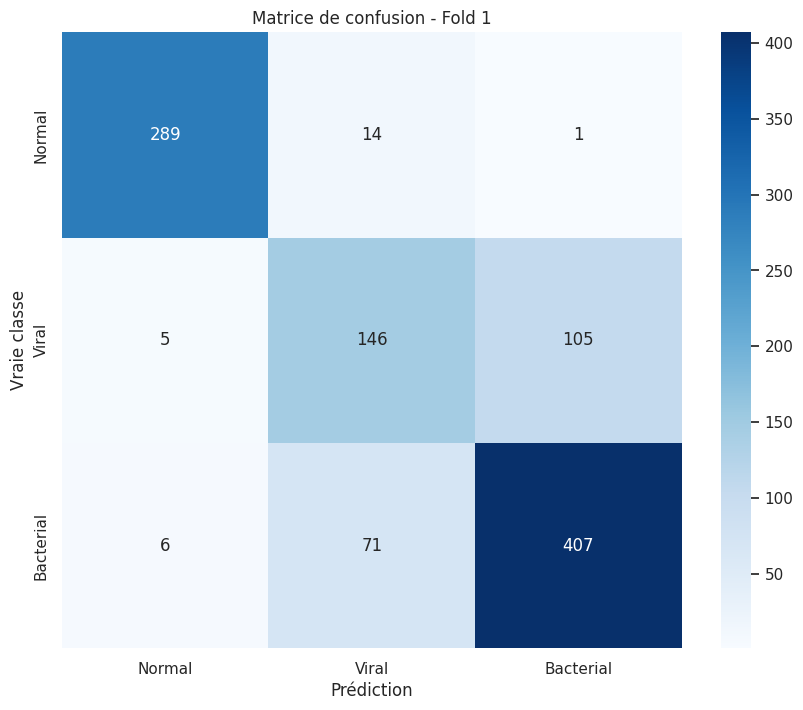


Métriques détaillées pour le Fold 1:

Classe: Normal
True Positives (TP): 289
True Negatives (TN): 729
False Positives (FP): 11
False Negatives (FN): 15
Precision: 0.9633
Recall: 0.9507

Classe: Viral
True Positives (TP): 146
True Negatives (TN): 703
False Positives (FP): 85
False Negatives (FN): 110
Precision: 0.6320
Recall: 0.5703

Classe: Bacterial
True Positives (TP): 407
True Negatives (TN): 454
False Positives (FP): 106
False Negatives (FN): 77
Precision: 0.7934
Recall: 0.8409

Rapport de classification détaillé:
              precision    recall  f1-score   support

      Normal       0.96      0.95      0.96       304
       Viral       0.63      0.57      0.60       256
   Bacterial       0.79      0.84      0.82       484

    accuracy                           0.81      1044
   macro avg       0.80      0.79      0.79      1044
weighted avg       0.80      0.81      0.80      1044



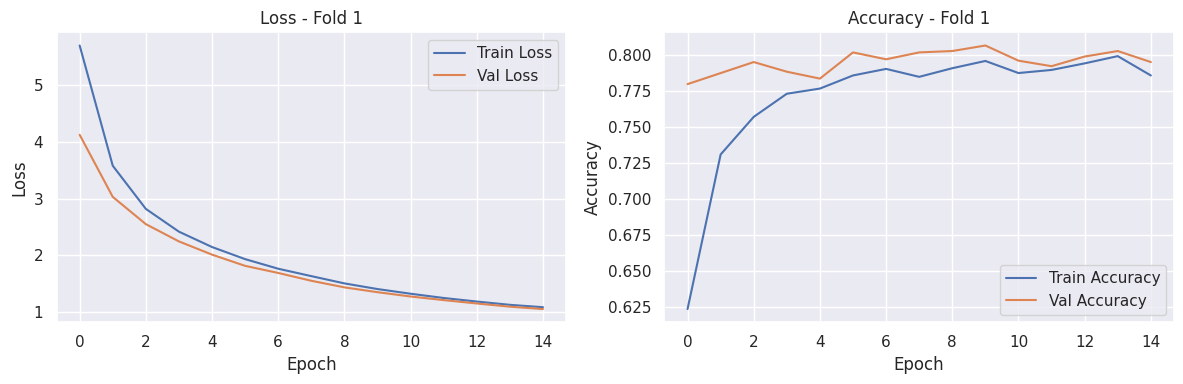

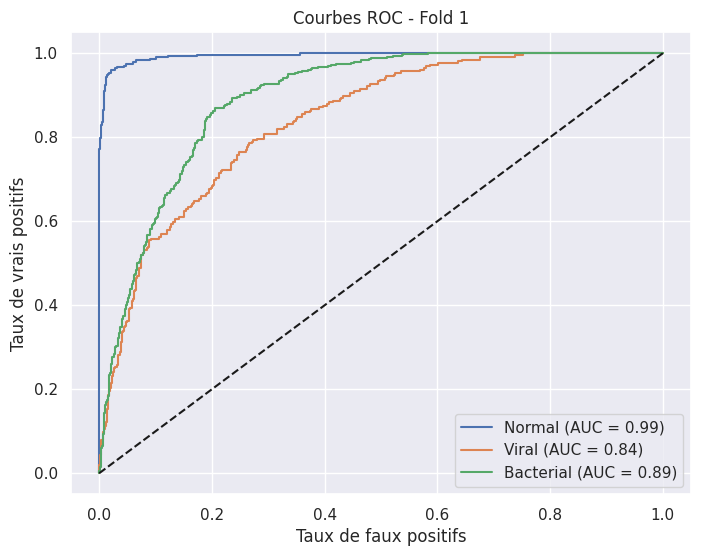

Fold 2/5


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 4, 4, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 256)            │     2,097,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,845,379 (64.26 MB)

 Trainable params: 2,130,691 (8.13 MB)

 Non-trainable params: 14,714,688 (56.13 MB)

Epoch 1/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 86ms/step - Precision: 0.6243 - Recall: 0.4402 - accuracy: 0.5573 - loss: 6.5580

2025-04-07 15:38:23.310882: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_276', 4 bytes spill stores, 4 bytes spill loads



131/131 ━━━━━━━━━━━━━━━━━━━━ 22s 145ms/step - Precision: 0.6249 - Recall: 0.4409 - accuracy: 0.5579 - loss: 6.5507 - val_Precision: 0.7968 - val_Recall: 0.7220 - val_accuracy: 0.7603 - val_loss: 4.0299 - learning_rate: 1.0000e-04
Epoch 2/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 9s 67ms/step - Precision: 0.7700 - Recall: 0.6867 - accuracy: 0.7392 - loss: 3.7480 - val_Precision: 0.7908 - val_Recall: 0.7392 - val_accuracy: 0.7718 - val_loss: 2.9362 - learning_rate: 1.0000e-04
Epoch 3/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 9s 65ms/step - Precision: 0.7716 - Recall: 0.7253 - accuracy: 0.7523 - loss: 2.8280 - val_Precision: 0.7883 - val_Recall: 0.7603 - val_accuracy: 0.7699 - val_loss: 2.4409 - learning_rate: 1.0000e-04
Epoch 4/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 9s 66ms/step - Precision: 0.7838 - Recall: 0.7425 - accuracy: 0.7649 - loss: 2.3964 - val_Precision: 0.7988 - val_Recall: 0.7766 - val_accuracy: 0.7919 - val_loss: 2.1181 - learning_rate: 1.0000e-04
Epoch 5/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 9s 66ms/step 

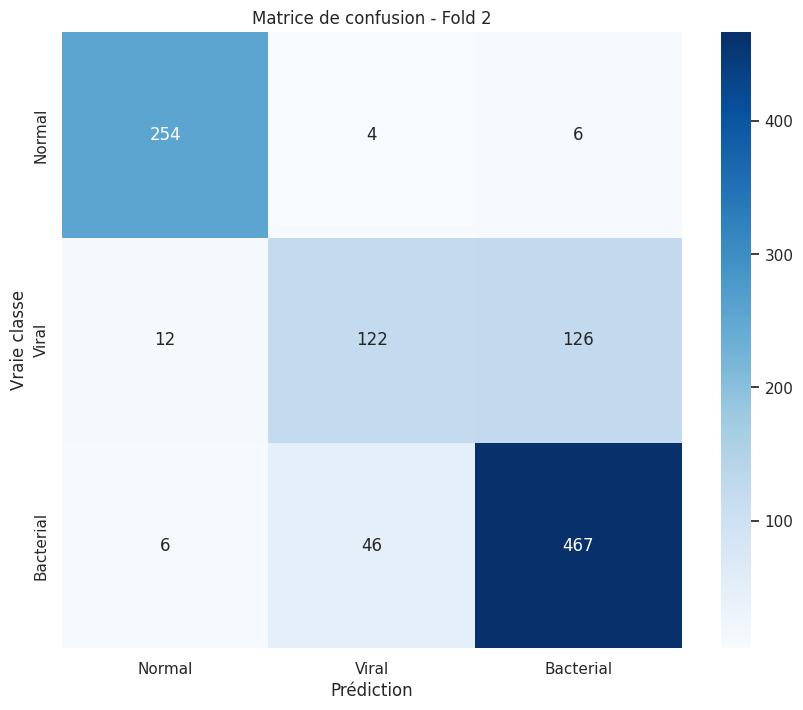


Métriques détaillées pour le Fold 2:

Classe: Normal
True Positives (TP): 254
True Negatives (TN): 761
False Positives (FP): 18
False Negatives (FN): 10
Precision: 0.9338
Recall: 0.9621

Classe: Viral
True Positives (TP): 122
True Negatives (TN): 733
False Positives (FP): 50
False Negatives (FN): 138
Precision: 0.7093
Recall: 0.4692

Classe: Bacterial
True Positives (TP): 467
True Negatives (TN): 392
False Positives (FP): 132
False Negatives (FN): 52
Precision: 0.7796
Recall: 0.8998

Rapport de classification détaillé:
              precision    recall  f1-score   support

      Normal       0.93      0.96      0.95       264
       Viral       0.71      0.47      0.56       260
   Bacterial       0.78      0.90      0.84       519

    accuracy                           0.81      1043
   macro avg       0.81      0.78      0.78      1043
weighted avg       0.80      0.81      0.80      1043



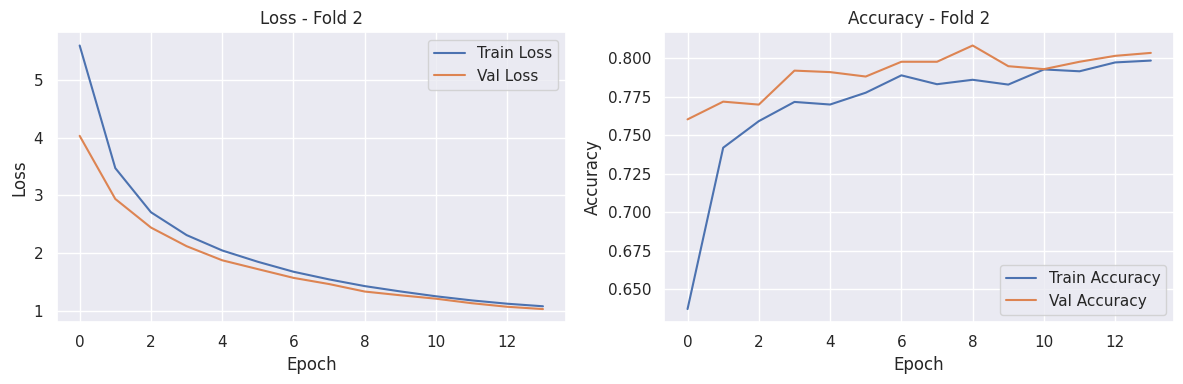

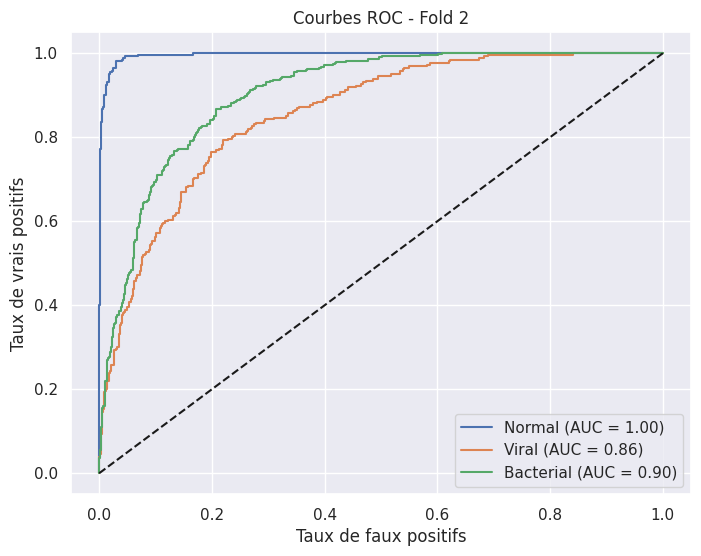

Fold 3/5


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 4, 4, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 256)            │     2,097,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,845,379 (64.26 MB)

 Trainable params: 2,130,691 (8.13 MB)

 Non-trainable params: 14,714,688 (56.13 MB)

Epoch 1/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 16s 98ms/step - Precision: 0.6186 - Recall: 0.4375 - accuracy: 0.5584 - loss: 6.5464 - val_Precision: 0.7489 - val_Recall: 0.6807 - val_accuracy: 0.7229 - val_loss: 4.1134 - learning_rate: 1.0000e-04
Epoch 2/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 9s 66ms/step - Precision: 0.7732 - Recall: 0.6916 - accuracy: 0.7446 - loss: 3.7764 - val_Precision: 0.7952 - val_Recall: 0.7593 - val_accuracy: 0.7824 - val_loss: 2.9609 - learning_rate: 1.0000e-04
Epoch 3/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 9s 67ms/step - Precision: 0.7783 - Recall: 0.7301 - accuracy: 0.7631 - loss: 2.8659 - val_Precision: 0.7984 - val_Recall: 0.7747 - val_accuracy: 0.7872 - val_loss: 2.4662 - learning_rate: 1.0000e-04
Epoch 4/15
 63/131 ━━━━━━━━━━━━━━━━━━━━ 3s 55ms/step - Precision: 0.7842 - Recall: 0.7358 - accuracy: 0.7602 - loss: 2.4643

In [ ]:
from sklearn.model_selection import KFold
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report

# Convertir les données en numpy arrays si ce n'est pas déjà fait
x_train_np = x_train.numpy() if isinstance(x_train, tf.Tensor) else x_train
y_train_np = y_train.numpy() if isinstance(y_train, tf.Tensor) else y_train

# Définir le nombre de folds
n_folds = 5
batch_size = 32
epochs = 15
kf = KFold(n_splits=n_folds, shuffle=True, random_state=42)
class_names = ['Normal', 'Viral', 'Bacterial']
# Boucle de validation croisée
val_scores = []

for fold, (train_idx, val_idx) in enumerate(kf.split(x_train_np)):
    print(f'Fold {fold + 1}/{n_folds}')
    
    model = create_model()
    
    # Utiliser les arrays numpy pour l'indexation
    x_train_fold = x_train_np[train_idx]
    y_train_fold = y_train_np[train_idx]
    x_val_fold = x_train_np[val_idx]
    y_val_fold = y_train_np[val_idx]
    
    # Convertir en tensors pour l'entraînement si nécessaire
    x_train_fold = tf.convert_to_tensor(x_train_fold)
    y_train_fold = tf.convert_to_tensor(y_train_fold)
    x_val_fold = tf.convert_to_tensor(x_val_fold)
    y_val_fold = tf.convert_to_tensor(y_val_fold)
    
    early_stopping = tf.keras.callbacks.EarlyStopping(
        monitor='val_accuracy',
        patience=5,
        restore_best_weights=True
    )
    
    reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.2,
        patience=3,
        min_lr=0.00001
    )

    history = model.fit(
        x_train_fold,
        y_train_fold,
        validation_data=(x_val_fold, y_val_fold),
        epochs=epochs,
        batch_size=batch_size,
        verbose=1,
        callbacks=[early_stopping, reduce_lr]
    )
    
    val_score = model.evaluate(x_val_fold, y_val_fold, verbose=0)
    val_scores.append(val_score[1])
    
    print(f"Fold {fold + 1} - Accuracy: {val_score[1]:.4f}")
    
     # Matrice de confusion avec plus de détails
    y_pred = model.predict(x_val_fold)
    y_pred_classes = np.argmax(y_pred, axis=1)
    y_true_classes = np.argmax(y_val_fold, axis=1)
    
    
    cm = confusion_matrix(y_true_classes, y_pred_classes)
    
    # Calculer TP, TN, FP, FN pour chaque classe
    n_classes = 3
    metrics = {}
    
    for i in range(n_classes):
        TP = cm[i, i]
        FP = np.sum(cm[:, i]) - TP
        FN = np.sum(cm[i, :]) - TP
        TN = np.sum(cm) - TP - FP - FN
        
        metrics[class_names[i]] = {
            'TP': TP,
            'TN': TN,
            'FP': FP,
            'FN': FN,
            'Precision': TP / (TP + FP) if (TP + FP) > 0 else 0,
            'Recall': TP / (TP + FN) if (TP + FN) > 0 else 0
        }
    
    # Afficher la matrice de confusion
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names,
                yticklabels=class_names)
    plt.title(f'Matrice de confusion - Fold {fold + 1}')
    plt.ylabel('Vraie classe')
    plt.xlabel('Prédiction')
    plt.show()
    
    # Afficher les métriques détaillées
    print(f"\nMétriques détaillées pour le Fold {fold + 1}:")
    for classe, m in metrics.items():
        print(f"\nClasse: {classe}")
        print(f"True Positives (TP): {m['TP']}")
        print(f"True Negatives (TN): {m['TN']}")
        print(f"False Positives (FP): {m['FP']}")
        print(f"False Negatives (FN): {m['FN']}")
        print(f"Precision: {m['Precision']:.4f}")
        print(f"Recall: {m['Recall']:.4f}")
    
    # Afficher le rapport de classification complet
    print("\nRapport de classification détaillé:")
    print(classification_report(y_true_classes, y_pred_classes, 
                              target_names=class_names))

    # --- Courbes d'entraînement/validation ---
    plt.figure(figsize=(12, 4))

    # Courbe de loss
    plt.subplot(1, 2, 1)
    plt.plot(history.history['loss'], label='Train Loss')
    plt.plot(history.history['val_loss'], label='Val Loss')
    plt.title(f'Loss - Fold {fold + 1}')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()

    # Courbe d'accuracy
    plt.subplot(1, 2, 2)
    plt.plot(history.history['accuracy'], label='Train Accuracy')
    plt.plot(history.history['val_accuracy'], label='Val Accuracy')
    plt.title(f'Accuracy - Fold {fold + 1}')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()

    plt.tight_layout()
    plt.show()

    # --- Courbe ROC par classe ---
    # Assurer que les labels sont one-hot encodés
    from sklearn.preprocessing import label_binarize
    from sklearn.metrics import roc_curve, auc

    if y_val_fold.shape[1] != len(class_names):  # besoin d'encoder
        y_val_bin = label_binarize(np.argmax(y_val_fold, axis=1), classes=[0, 1, 2])
    else:
        y_val_bin = y_val_fold.numpy() if isinstance(y_val_fold, tf.Tensor) else y_val_fold

    fpr = dict()
    tpr = dict()
    roc_auc = dict()

    for i in range(len(class_names)):
        fpr[i], tpr[i], _ = roc_curve(y_val_bin[:, i], y_pred[:, i])
        roc_auc[i] = auc(fpr[i], tpr[i])

    plt.figure(figsize=(8, 6))
    for i in range(len(class_names)):
        plt.plot(fpr[i], tpr[i], label=f"{class_names[i]} (AUC = {roc_auc[i]:.2f})")
    plt.plot([0, 1], [0, 1], 'k--')
    plt.title(f'Courbes ROC - Fold {fold + 1}')
    plt.xlabel('Taux de faux positifs')
    plt.ylabel('Taux de vrais positifs')
    plt.legend(loc='lower right')
    plt.grid(True)
    plt.show()
                              
   

print("\nRésultats finaux:")
print(f"Score moyen: {np.mean(val_scores):.4f} (+/- {np.std(val_scores):.4f})")

In [8]:
# Save the model
model.save('CNN_model.h5')